In [1]:
!pip install gensim

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 15.4 MB/s  0:00:01


In [2]:
import gensim
from gensim.models import Word2Vec, KeyedVectors

In [3]:
import gensim.downloader as api

wv = api.load('word2vec-google-news-300')

vec_king = wv['king']

[==================================================] 100.0% 1662.8/1662.8MB downloaded


In [31]:
vec_king

array([ 1.25976562e-01,  2.97851562e-02,  8.60595703e-03,  1.39648438e-01,
       -2.56347656e-02, -3.61328125e-02,  1.11816406e-01, -1.98242188e-01,
        5.12695312e-02,  3.63281250e-01, -2.42187500e-01, -3.02734375e-01,
       -1.77734375e-01, -2.49023438e-02, -1.67968750e-01, -1.69921875e-01,
        3.46679688e-02,  5.21850586e-03,  4.63867188e-02,  1.28906250e-01,
        1.36718750e-01,  1.12792969e-01,  5.95703125e-02,  1.36718750e-01,
        1.01074219e-01, -1.76757812e-01, -2.51953125e-01,  5.98144531e-02,
        3.41796875e-01, -3.11279297e-02,  1.04492188e-01,  6.17675781e-02,
        1.24511719e-01,  4.00390625e-01, -3.22265625e-01,  8.39843750e-02,
        3.90625000e-02,  5.85937500e-03,  7.03125000e-02,  1.72851562e-01,
        1.38671875e-01, -2.31445312e-01,  2.83203125e-01,  1.42578125e-01,
        3.41796875e-01, -2.39257812e-02, -1.09863281e-01,  3.32031250e-02,
       -5.46875000e-02,  1.53198242e-02, -1.62109375e-01,  1.58203125e-01,
       -2.59765625e-01,  

In [32]:
vec_king.shape

(300,)

In [33]:
import pandas as pd
messages=pd.read_csv('SMSSpamCollection.txt',
                    sep='\t',names=["label","message"])

In [34]:
messages.shape

(5572, 2)

In [35]:
from nltk.stem import WordNetLemmatizer
lemmatizer=WordNetLemmatizer()

In [36]:
import re
import nltk
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')
nltk.download('punkt')
nltk.download('punkt_tab')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [37]:
from nltk.corpus import stopwords
stop_words = set(stopwords.words('english'))

corpus = []
for i in range(0, len(messages)):
    review = re.sub('[^a-zA-Z]', ' ', messages['message'][i])
    review = review.lower()
    review = review.split()

    review = [lemmatizer.lemmatize(word) for word in review if word not in stop_words]
    review = ' '.join(review)
    corpus.append(review)

In [38]:
corpus

['go jurong point crazy available bugis n great world la e buffet cine got amore wat',
 'ok lar joking wif u oni',
 'free entry wkly comp win fa cup final tkts st may text fa receive entry question std txt rate c apply',
 'u dun say early hor u c already say',
 'nah think go usf life around though',
 'freemsg hey darling week word back like fun still tb ok xxx std chgs send rcv',
 'even brother like speak treat like aid patent',
 'per request melle melle oru minnaminunginte nurungu vettam set callertune caller press copy friend callertune',
 'winner valued network customer selected receivea prize reward claim call claim code kl valid hour',
 'mobile month u r entitled update latest colour mobile camera free call mobile update co free',
 'gonna home soon want talk stuff anymore tonight k cried enough today',
 'six chance win cash pound txt csh send cost p day day tsandcs apply reply hl info',
 'urgent week free membership prize jackpot txt word claim c www dbuk net lccltd pobox ldnw rw'

In [46]:
type(corpus)

list

In [39]:
from nltk import sent_tokenize
from gensim.utils import simple_preprocess

In [40]:
words=[]
for sent in corpus:
    sent_token=sent_tokenize(sent)
    for sent in sent_token:
        words.append(simple_preprocess(sent))


In [41]:
words

[['go',
  'jurong',
  'point',
  'crazy',
  'available',
  'bugis',
  'great',
  'world',
  'la',
  'buffet',
  'cine',
  'got',
  'amore',
  'wat'],
 ['ok', 'lar', 'joking', 'wif', 'oni'],
 ['free',
  'entry',
  'wkly',
  'comp',
  'win',
  'fa',
  'cup',
  'final',
  'tkts',
  'st',
  'may',
  'text',
  'fa',
  'receive',
  'entry',
  'question',
  'std',
  'txt',
  'rate',
  'apply'],
 ['dun', 'say', 'early', 'hor', 'already', 'say'],
 ['nah', 'think', 'go', 'usf', 'life', 'around', 'though'],
 ['freemsg',
  'hey',
  'darling',
  'week',
  'word',
  'back',
  'like',
  'fun',
  'still',
  'tb',
  'ok',
  'xxx',
  'std',
  'chgs',
  'send',
  'rcv'],
 ['even', 'brother', 'like', 'speak', 'treat', 'like', 'aid', 'patent'],
 ['per',
  'request',
  'melle',
  'melle',
  'oru',
  'minnaminunginte',
  'nurungu',
  'vettam',
  'set',
  'callertune',
  'caller',
  'press',
  'copy',
  'friend',
  'callertune'],
 ['winner',
  'valued',
  'network',
  'customer',
  'selected',
  'receivea',
 

In [42]:
import gensim

In [55]:
## Lets train Word2vec from scratch
model=gensim.models.Word2Vec(words,epochs=200)

In [56]:
model.corpus_count

5564

In [57]:
## To Get All the Vocabulary
model.wv.index_to_key

['call',
 'get',
 'ur',
 'gt',
 'lt',
 'go',
 'day',
 'ok',
 'free',
 'know',
 'come',
 'like',
 'good',
 'time',
 'got',
 'love',
 'text',
 'want',
 'send',
 'one',
 'need',
 'txt',
 'today',
 'going',
 'stop',
 'home',
 'lor',
 'sorry',
 'see',
 'still',
 'mobile',
 'take',
 'back',
 'da',
 'reply',
 'dont',
 'think',
 'tell',
 'week',
 'phone',
 'hi',
 'new',
 'later',
 'please',
 'pls',
 'co',
 'msg',
 'min',
 'dear',
 'night',
 'make',
 'message',
 'well',
 'say',
 'thing',
 'much',
 'hope',
 'oh',
 'claim',
 'great',
 'hey',
 'number',
 'give',
 'happy',
 'work',
 'friend',
 'wat',
 'way',
 'yes',
 'www',
 'let',
 'prize',
 'right',
 'tomorrow',
 'already',
 'tone',
 'said',
 'ask',
 'win',
 'amp',
 'cash',
 'life',
 'im',
 'yeah',
 'really',
 'babe',
 'meet',
 'find',
 'miss',
 'morning',
 'last',
 'service',
 'year',
 'uk',
 'thanks',
 'care',
 'would',
 'anything',
 'com',
 'also',
 'nokia',
 'lol',
 'every',
 'feel',
 'keep',
 'pick',
 'sure',
 'sent',
 'contact',
 'urgent',


In [58]:
model.epochs

200

In [59]:
model.wv.similar_by_word('good')

[('love', 0.4104982614517212),
 ('brings', 0.3650822341442108),
 ('thank', 0.36314937472343445),
 ('great', 0.35947906970977783),
 ('spent', 0.3230278491973877),
 ('well', 0.322535902261734),
 ('thanks', 0.31609079241752625),
 ('another', 0.3033103942871094),
 ('hows', 0.29117351770401),
 ('sweet', 0.2872765362262726)]

In [60]:
model.wv['good'].shape

(100,)

In [61]:
model.wv['man']

array([-0.81173885, -1.1045092 , -0.5772485 ,  0.60523415,  0.92463756,
       -2.5585384 ,  0.42459905,  0.49664807, -0.9981721 , -0.15415977,
        0.583692  ,  4.1078525 , -2.7274995 ,  0.32245085, -0.2912737 ,
       -1.7478204 ,  1.362866  , -0.04567346,  0.8658994 ,  2.23773   ,
       -0.67717886,  0.757619  ,  1.264685  ,  1.9360942 , -1.3476179 ,
       -2.4427102 ,  0.69191545, -0.07548504,  0.23263463, -1.6874249 ,
        2.1324844 ,  2.574757  ,  0.1579217 ,  1.6204323 ,  2.4007766 ,
       -0.7826998 ,  0.42656362, -1.0561692 , -0.9714749 ,  1.866327  ,
        1.5014901 ,  0.29689485,  0.39751557, -1.3900608 , -0.8643126 ,
        0.10372491,  1.8837252 ,  0.8453981 ,  0.16552028, -2.0885289 ,
        0.9728707 ,  1.2676902 , -1.0330291 ,  0.37801984, -1.5137382 ,
       -1.9290614 , -1.4782972 ,  2.4506054 ,  1.8523244 , -2.379534  ,
       -0.22788338, -1.6312279 ,  0.9821352 , -2.129832  ,  1.4364252 ,
        0.03009628,  2.589292  ,  2.5681837 ,  0.21182226,  0.27

In [62]:
model.wv['man'].shape

(100,)

In [63]:
words[0]

['go',
 'jurong',
 'point',
 'crazy',
 'available',
 'bugis',
 'great',
 'world',
 'la',
 'buffet',
 'cine',
 'got',
 'amore',
 'wat']

In [64]:
def avg_word2vec(doc):
    # remove out-of-vocabulary words
    vecs = [model.wv[word] for word in doc if word in model.wv.key_to_index]
    # return zeros (not NaN) when no word of the doc is in the vocabulary
    return np.mean(vecs, axis=0) if len(vecs) > 0 else np.zeros(model.vector_size)

In [65]:
!pip install tqdm

In [66]:
from tqdm import tqdm

In [67]:
#apply for the entire sentences
import numpy as np
X=[]
for i in tqdm(range(len(words))):
    X.append(avg_word2vec(words[i]))

100%|██████████| 5564/5564 [00:00<00:00, 20393.19it/s]


In [68]:
len(X)

5564

In [69]:
X[0]

array([ 0.10322719, -0.31742048,  0.15823697, -0.3723872 , -0.7093297 ,
        0.05168945, -0.10206366,  0.167676  , -0.3345994 , -0.535526  ,
        0.37253016, -0.05824417,  0.22998518,  0.1466863 ,  0.26450542,
        0.00216966, -0.72293085, -0.9735664 ,  0.2495868 , -0.38002205,
       -0.34008732,  0.5447546 ,  0.0557974 , -0.10023269, -0.30412892,
        0.5665826 ,  0.18761243, -0.83288664, -0.169428  ,  0.03683226,
       -0.01678979, -0.39558223,  0.43450257, -0.23927584, -0.33405975,
        1.101357  , -0.05204487,  0.08170956, -0.08085521,  0.44180366,
        0.528544  ,  0.06024716,  0.32566702,  0.07340577, -0.8372547 ,
       -0.32668164, -0.27016315,  0.34577462, -0.5633503 ,  0.46565238,
       -0.17502159,  0.0968494 ,  0.10891919, -0.7436402 ,  0.06515341,
       -0.912973  ,  1.3743284 , -0.17234689, -0.6197381 , -0.13959782,
        0.0209088 , -0.27537748,  0.15026864, -0.18853976, -0.6546673 ,
        0.0260258 , -0.23636808, -0.17840396,  0.2533718 ,  0.04

In [70]:
##independent Features
X_new=np.array(X)

In [71]:
messages.shape

(5572, 2)

In [72]:
X[1]

array([ 0.6858988 ,  0.40644327, -0.12337792, -0.33896282,  0.07812411,
       -0.64482296,  0.4684809 , -0.95962554, -0.69874287,  0.20619364,
       -0.6111871 ,  1.7332656 ,  0.6102295 ,  0.85867316,  0.73140824,
        0.03714649,  0.4777711 ,  0.22091842, -0.9652989 , -0.13280863,
       -0.5648145 ,  1.1549535 ,  1.127215  , -1.2171718 , -1.1212196 ,
       -0.73882747, -1.1537625 , -1.4173164 , -0.852224  ,  1.6373296 ,
       -0.18253562,  0.4399415 , -0.45409852, -0.69891053, -0.19083679,
        0.90829766, -1.54651   ,  0.7854144 , -1.65398   , -0.09248389,
        0.4504569 ,  0.71639645, -0.93389165,  0.4061763 ,  0.3710383 ,
       -1.2335902 ,  0.25882113,  0.2302241 ,  1.3877791 ,  0.32567364,
        0.22992456,  0.51157963,  0.17392266,  0.34807652,  0.87052315,
        0.3857814 , -0.04943189,  0.48779768, -0.23149022,  0.88057685,
        0.07914783, -0.916525  ,  1.0996492 ,  1.3873551 , -0.88907576,
        0.8702187 ,  0.73847085, -1.5900488 , -0.7796816 ,  0.27

In [73]:
X_new.shape

(5564, 100)

In [74]:
X_new[0].shape

(100,)

In [92]:
## Dependent Features
## Output Features

y = messages[list(map(lambda x: len(x) > 0, corpus))]

y = (y['label'] == 'spam').astype(int).values

In [93]:
y.shape

(5564,)

In [94]:
X[0].reshape(1,-1).shape

(1, 100)

In [95]:
## this is the final independent features
df=pd.DataFrame(X)

In [96]:
df.head()

,0,1,2,3,4,5,6,7,8,9,...,90,91,92,93,94,95,96,97,98,99
0,0.103227,-0.317420,0.158237,-0.372387,-0.709330,0.051689,-0.102064,0.167676,-0.334599,-0.535526,...,0.557489,0.511621,-0.363792,0.996567,0.740140,-0.172545,-0.447869,-0.094240,0.118371,0.859187
1,0.685899,0.406443,-0.123378,-0.338963,0.078124,-0.644823,0.468481,-0.959626,-0.698743,0.206194,...,-0.485972,-0.027866,0.795523,0.967930,1.061511,0.056118,1.181522,-0.075897,0.429344,-0.143486
2,-0.149671,0.853968,1.692087,0.906471,1.081658,-0.240516,0.308430,0.493667,-0.605668,0.071870,...,-0.271193,-1.081151,-0.986754,-1.297915,0.451555,0.089341,-1.373427,-0.494073,0.764089,-0.757056
3,-0.224694,0.047082,0.188270,0.099092,-0.437133,-1.338315,-0.343316,0.146059,-1.197082,-0.680123,...,-0.148068,1.192603,0.092030,0.393230,-0.176222,-0.231959,-0.522442,0.297503,-0.302218,0.361348
4,-1.071257,-0.330536,-0.874848,0.817914,1.223665,0.847980,0.306967,0.106964,0.001836,0.730354,...,-0.029214,0.323902,0.180827,0.157994,0.169246,-0.958661,0.516094,-0.050370,0.405976,0.642225


In [97]:
df['Output']=y

In [98]:
df.head()

,0,1,2,3,4,5,6,7,8,9,...,91,92,93,94,95,96,97,98,99,Output
0,0.103227,-0.317420,0.158237,-0.372387,-0.709330,0.051689,-0.102064,0.167676,-0.334599,-0.535526,...,0.511621,-0.363792,0.996567,0.740140,-0.172545,-0.447869,-0.094240,0.118371,0.859187,0
1,0.685899,0.406443,-0.123378,-0.338963,0.078124,-0.644823,0.468481,-0.959626,-0.698743,0.206194,...,-0.027866,0.795523,0.967930,1.061511,0.056118,1.181522,-0.075897,0.429344,-0.143486,0
2,-0.149671,0.853968,1.692087,0.906471,1.081658,-0.240516,0.308430,0.493667,-0.605668,0.071870,...,-1.081151,-0.986754,-1.297915,0.451555,0.089341,-1.373427,-0.494073,0.764089,-0.757056,1
3,-0.224694,0.047082,0.188270,0.099092,-0.437133,-1.338315,-0.343316,0.146059,-1.197082,-0.680123,...,1.192603,0.092030,0.393230,-0.176222,-0.231959,-0.522442,0.297503,-0.302218,0.361348,0
4,-1.071257,-0.330536,-0.874848,0.817914,1.223665,0.847980,0.306967,0.106964,0.001836,0.730354,...,0.323902,0.180827,0.157994,0.169246,-0.958661,0.516094,-0.050370,0.405976,0.642225,0


In [99]:
df.dropna(inplace=True)

In [100]:
df.isnull().sum()

,0
0,0
1,0
2,0
3,0
4,0
...,...
96,0
97,0
98,0
99,0


In [101]:
## Independent Feature
X=df.drop('Output',axis=1)

In [102]:
X

,0,1,2,3,4,5,6,7,8,9,...,90,91,92,93,94,95,96,97,98,99
0,0.103227,-0.317420,0.158237,-0.372387,-0.709330,0.051689,-0.102064,0.167676,-0.334599,-0.535526,...,0.557489,0.511621,-0.363792,0.996567,0.740140,-0.172545,-0.447869,-0.094240,0.118371,0.859187
1,0.685899,0.406443,-0.123378,-0.338963,0.078124,-0.644823,0.468481,-0.959626,-0.698743,0.206194,...,-0.485972,-0.027866,0.795523,0.967930,1.061511,0.056118,1.181522,-0.075897,0.429344,-0.143486
2,-0.149671,0.853968,1.692087,0.906471,1.081658,-0.240516,0.308430,0.493667,-0.605668,0.071870,...,-0.271193,-1.081151,-0.986754,-1.297915,0.451555,0.089341,-1.373427,-0.494073,0.764089,-0.757056
3,-0.224694,0.047082,0.188270,0.099092,-0.437133,-1.338315,-0.343316,0.146059,-1.197082,-0.680123,...,-0.148068,1.192603,0.092030,0.393230,-0.176222,-0.231959,-0.522442,0.297503,-0.302218,0.361348
4,-1.071257,-0.330536,-0.874848,0.817914,1.223665,0.847980,0.306967,0.106964,0.001836,0.730354,...,-0.029214,0.323902,0.180827,0.157994,0.169246,-0.958661,0.516094,-0.050370,0.405976,0.642225
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5559,-1.372499,0.821096,0.416541,0.339202,-0.373670,1.283260,-0.212930,0.750778,-0.334803,-0.302940,...,0.098619,-0.773024,0.148335,-0.426969,1.941094,0.550474,-1.162563,1.831685,0.710456,-1.281291
5560,0.616957,-0.274412,0.252509,-2.245212,-0.992112,-0.511115,0.301823,0.671821,-0.141316,0.367578,...,0.838986,-0.416860,0.150765,0.060375,-0.594103,-0.189065,1.744804,-0.375507,-0.648517,1.200321
5561,-0.276000,1.357696,-0.107167,0.562077,-0.037690,-0.571434,0.397491,0.550278,0.937708,1.176764,...,-1.108425,-0.606803,-0.750191,-1.304994,-0.440524,0.505270,-0.574390,0.829565,0.568098,-2.058180
5562,-0.337519,-0.588307,0.248795,0.914961,0.379891,0.010854,-0.165333,0.238980,0.130087,0.050343,...,0.474597,-0.684518,0.176930,-0.275483,0.374067,-0.384545,-0.444946,0.054096,0.180710,0.266208


In [103]:
y=df['Output']

In [104]:
y

,Output
0,0
1,0
2,1
3,0
4,0
...,...
5559,1
5560,0
5561,0
5562,0


In [105]:
## Train Test Split
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.20,random_state=42)

In [106]:
X_train.head()

,0,1,2,3,4,5,6,7,8,9,...,90,91,92,93,94,95,96,97,98,99
1730,-0.586715,-2.190784,-0.590950,-0.248489,1.851352,-1.881238,-0.050936,0.375275,0.855058,1.006464,...,0.744985,-0.091300,0.293213,0.454736,0.518901,-1.164484,1.220605,1.599769,-0.510836,1.126719
5123,-0.401271,-0.081049,0.101294,0.712812,0.305219,0.143204,0.308696,-0.486121,-0.154265,-0.559009,...,-0.194117,0.319740,-0.380953,-0.060147,0.200740,-1.062013,0.894763,-0.464839,-0.080185,0.363415
1476,-0.799943,-0.402888,0.395005,0.721010,1.374908,0.087646,-0.592359,-0.955984,0.368186,-0.264083,...,0.300906,-0.069596,-1.023327,-0.604695,0.597902,-1.195746,0.247188,-0.343438,1.010453,0.383189
2867,-1.177317,0.293674,1.002274,-0.008716,-0.700749,0.886494,0.803055,0.653079,-0.360418,-0.414472,...,-0.958103,-0.413493,-0.048379,-0.615941,1.013053,0.515923,-0.120692,0.020540,0.163405,-1.876056
4896,-0.227082,-0.561498,-0.730587,-0.757672,-0.706350,1.175485,2.495155,-0.900995,-0.641041,-1.100814,...,-0.446393,-0.078260,0.676191,0.658239,0.269208,0.313589,0.420861,-0.257001,0.043585,-0.351693


In [107]:
y_train

,Output
1730,0
5123,0
1476,0
2867,1
4896,0
...,...
3772,0
5191,0
5226,0
5390,0


In [108]:
from sklearn.naive_bayes import MultinomialNB, BernoulliNB, ComplementNB

from sklearn.linear_model import LogisticRegression

from sklearn.svm import LinearSVC

from sklearn.ensemble import RandomForestClassifier

from sklearn.tree import DecisionTreeClassifier

from sklearn.neighbors import KNeighborsClassifier

In [111]:
models = {
    'BernoulliNB': BernoulliNB(),
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'SVM': LinearSVC(),
    'Random Forest': RandomForestClassifier(),
    'Decision Tree': DecisionTreeClassifier(),
    'KNN': KNeighborsClassifier()
}

results = {}

for name, model in models.items():

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    results[name] = y_pred

    print(f"{name} trained successfully")

BernoulliNB trained successfully
Logistic Regression trained successfully
SVM trained successfully
Random Forest trained successfully
Decision Tree trained successfully
KNN trained successfully


In [112]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

model_results = []

for name, model in models.items():

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    model_results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1 Score': f1_score(y_test, y_pred)
    })

results_df = pd.DataFrame(model_results)

results_df = results_df.sort_values(
    by='F1 Score',
    ascending=False
)

display(results_df)

,Model,Accuracy,Precision,Recall,F1 Score
3,Random Forest,0.980234,0.970149,0.878378,0.921986
5,KNN,0.966757,0.849057,0.912162,0.879479
2,SVM,0.965858,0.876712,0.864865,0.870748
1,Logistic Regression,0.964061,0.880282,0.844595,0.862069
4,Decision Tree,0.960467,0.846667,0.858108,0.852349
0,BernoulliNB,0.955076,0.795181,0.891892,0.840764


In [113]:
best_model_name = results_df.iloc[0]['Model']
best_model = models[best_model_name]

print("Best Model:", best_model_name)
print("Best F1 Score:", results_df.iloc[0]['F1 Score'])

Best Model: Random Forest
Best F1 Score: 0.9219858156028369


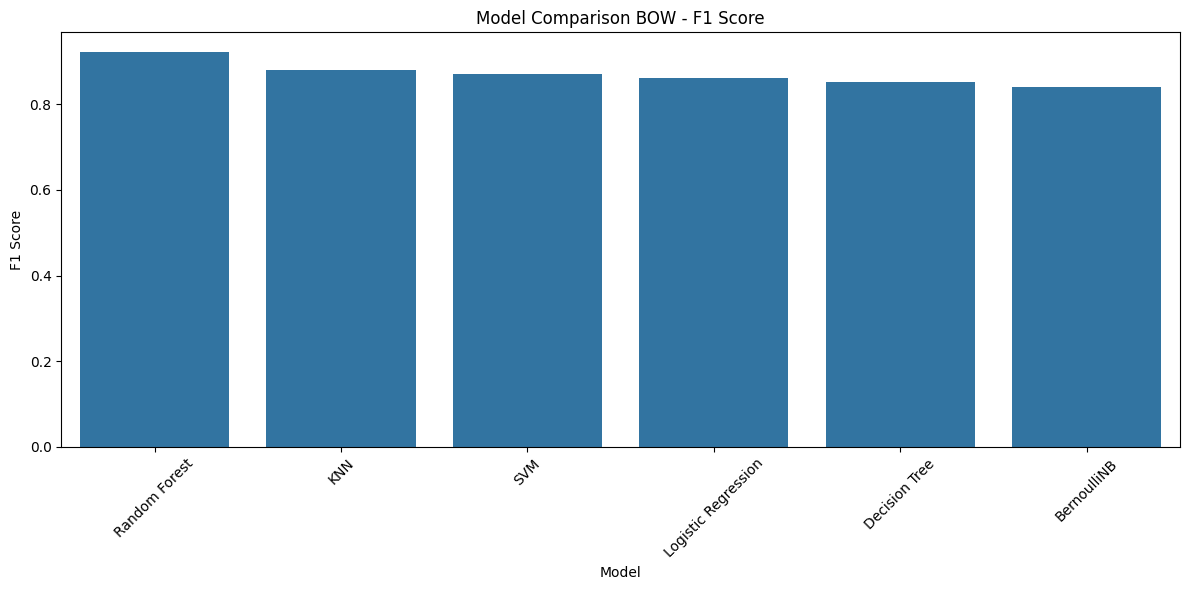

In [114]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))

sns.barplot(
    data=results_df,
    x='Model',
    y='F1 Score'
)

plt.xticks(rotation=45)
plt.title('Model Comparison BOW - F1 Score')
plt.tight_layout()
plt.show()